# Video Game Sales: Perbandingan Pasar Regional, Prediksi Penjualan, dan Segmentasi K-Means
Notebook akhir yang menggantikan `video-game-sales.ipynb`. Semua langkah analisis memanggil fungsi di `rq_pipeline.py`,
sehingga angka di notebook, di `app.py`, dan di naskah berasal dari satu sumber.

**Pertanyaan penelitian**
- **RQ1** Bagaimana pola penjualan menurut genre dan platform berbeda antara Amerika Utara, Eropa, dan Jepang?
- **RQ2** Sejauh mana genre, platform, publisher, dan tahun rilis dapat memprediksi penjualan global, dan atribut mana yang paling informatif?
- **RQ3** Segmen apa yang terbentuk dari pola penjualan regional dengan K-Means, dan bagaimana karakteristiknya?

**Perbedaan penting dari notebook lama**
1. Pembagian data **per judul** (`GroupKFold`), bukan per baris: versi platform lain dari judul yang sama tidak pernah tersebar ke data latih dan uji.
2. Median tahun, pooling publisher, dan scaler dihitung dari **data latih saja** di setiap fold.
3. Fitur hanya atribut produk (Year, Platform, Genre, Publisher). Kolom penjualan, `Rank`, dan `Name` tidak dipakai.
4. Evaluasi memakai **MAE, RMSE, dan R²** (rata-rata ± simpangan baku antar fold) dan dibandingkan dengan baseline mean dan median.
5. Segmentasi memakai log-penjualan NA/EU/JP yang distandardisasi, dengan validasi elbow, silhouette, Davies-Bouldin, dan stabilitas (ARI).
6. MLP memakai `scikit-learn` (`MLPRegressor`, 128-128, early stopping), bukan Keras, agar notebook tidak bergantung pada TensorFlow.

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

import rq_pipeline as rq            # file rq_pipeline.py harus berada di folder yang sama

# --- Konfigurasi sumber data (pilih salah satu) ---
SQL_FILE  = os.environ.get("VGS_SQL", "video_game_sales.sql")   # dump SQL
MYSQL_URL = os.environ.get("VGS_DB_URL")                        # contoh: "mysql+pymysql://root:@localhost:3306/video_game_sales"
CSV_FILE  = os.environ.get("VGS_CSV")                           # opsional: vgsales.csv untuk audit sumber ganda
OUT       = "hasil"                                             # folder keluaran (dibaca juga oleh app.py)
QUICK     = False                                               # True = Random Forest 60 pohon (uji cepat)
K         = None                                                # None = pilih otomatis; isi 3 untuk memaksa k=3

os.makedirs(OUT, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
print("siap. SQL:", SQL_FILE, "| MySQL:", bool(MYSQL_URL), "| CSV audit:", bool(CSV_FILE))

siap. SQL: /mnt/user-data/attachments/935d25ec-ce2b-53b3-96ec-9de825e4faae/c56d15eb-1793539670282_video_game_sales.sql | MySQL: False | CSV audit: True


## 1. Data dan audit
Data dimuat dari MySQL (jika `VGS_DB_URL` diisi) atau dari dump SQL. `build_flat` menggabungkan lima tabel dan
mengoreksi dua baris `game_sales` yang menunjuk `game_id` dengan genre salah (Syndicate PC 1992 dan
Little Busters! Converted Edition PSV). Koreksi bersifat idempoten: tidak berpengaruh jika `fix_genre_pointers.sql` sudah dijalankan.

In [2]:
T = rq.load_tables(mysql=MYSQL_URL) if MYSQL_URL else rq.load_tables(sql=SQL_FILE)
df, n_fix = rq.build_flat(T)

audit = pd.Series({
    "Record (judul x platform)": f"{len(df):,}",
    "Judul unik": f"{df['Name'].nunique():,}",
    "Baris tabel game / publisher": f"{len(T['game']):,} / {len(T['publisher']):,}",
    "Platform / genre": f"{df['Platform'].nunique()} / {df['Genre'].nunique()}",
    "Tahun rilis kosong": f"{int(df['Year'].isna().sum()):,} ({df['Year'].isna().mean():.2%})",
    "Publisher 'N/A' atau 'Unknown' (bukan NaN)": f"{int(df['Publisher'].isin(['N/A','Unknown']).sum()):,}",
    "Duplikat (judul, platform)": int(df.duplicated(['Name', 'Platform']).sum()),
    "Penunjuk genre dikoreksi": n_fix,
}, name="Nilai")
print(audit.to_string())
df.head()

Record (judul x platform)                           16,598
Judul unik                                          11,493
Baris tabel game / publisher                  11,921 / 579
Platform / genre                                   31 / 12
Tahun rilis kosong                             271 (1.63%)
Publisher 'N/A' atau 'Unknown' (bukan NaN)             261
Duplikat (judul, platform)                               5
Penunjuk genre dikoreksi                                 2
   Rank                      Name Platform    Year         Genre Publisher  NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales
0     1                Wii Sports      Wii  2006.0        Sports  Nintendo     41.49     29.02      3.77         8.46         82.74
1     2         Super Mario Bros.      NES  1985.0      Platform  Nintendo     29.08      3.58      6.81         0.77         40.24
2     3            Mario Kart Wii      Wii  2008.0        Racing  Nintendo     15.85     12.88      3.79         3.31         35.82


In [3]:
# Audit sumber ganda: bandingkan dengan CSV Kaggle (hanya jika CSV_FILE diisi).
# Catatan: judul yang mengandung ';' pada CSV ber-pemisah ';' tanpa tanda kutip terpotong dan kolom setelahnya kosong.
if CSV_FILE and os.path.exists(CSV_FILE):
    cols = ["Rank","Name","Platform","Year","Genre","Publisher","NA_Sales","EU_Sales","JP_Sales","Other_Sales","Global_Sales"]
    lines = open(CSV_FILE, encoding="utf8", errors="replace").read().splitlines()[1:]
    sep = ";" if open(CSV_FILE, encoding="utf8", errors="replace").readline().count(";") >= 10 else ","
    rows = [l.split(sep) for l in lines if l.strip()]
    csv = pd.DataFrame(rows, columns=cols)
    for c in ["Rank","NA_Sales","EU_Sales","JP_Sales","Other_Sales","Global_Sales"]:
        csv[c] = pd.to_numeric(csv[c], errors="coerce")
    csv["Year"] = pd.to_numeric(csv["Year"], errors="coerce")
    damaged = csv["Global_Sales"].isna()
    ok = csv[~damaged].set_index("Rank")
    m = df.set_index("Rank").loc[ok.index]
    report = {"baris CSV": len(csv), "baris CSV rusak (kolom kosong)": int(damaged.sum()), "baris dibandingkan": len(ok)}
    for c in ["NA_Sales","EU_Sales","JP_Sales","Other_Sales","Global_Sales"]:
        report[f"selisih {c} > 0.005"] = int(((m[c] - ok[c]).abs() > 0.005).sum())
    report["selisih Year"] = int(((m["Year"] != ok["Year"]) & ~(m["Year"].isna() & ok["Year"].isna())).sum())
    for c in ["Name","Platform","Genre","Publisher"]:
        report[f"selisih {c}"] = int((m[c].astype(str) != ok[c].astype(str)).sum())
    print(pd.Series(report).to_string())
else:
    print("Audit CSV dilewati (isi CSV_FILE / variabel lingkungan VGS_CSV untuk menjalankannya).")

baris CSV                         16598
baris CSV rusak (kolom kosong)       26
baris dibandingkan                16572
selisih NA_Sales > 0.005              0
selisih EU_Sales > 0.005              0
selisih JP_Sales > 0.005              0
selisih Other_Sales > 0.005           0
selisih Global_Sales > 0.005          0
selisih Year                          0
selisih Name                          0
selisih Platform                      0
selisih Genre                         0
selisih Publisher                     0


## 2. RQ1: Pola penjualan regional
`rq.rq1` menghitung pangsa wilayah, korelasi Spearman antar wilayah, komposisi genre dan platform per wilayah, jarak
Jensen-Shannon antar wilayah (0 = komposisi identik, 1 = berbeda total), dan interval kepercayaan bootstrap per judul.
Pangsa dilaporkan dengan dua penyebut (empat wilayah, atau NA+EU+JP saja); sebutkan penyebutnya di naskah.

In [4]:
R1 = rq.rq1(df, OUT)


RQ1 -- Pola penjualan genre & platform: NA vs EU vs JP
  Total (juta): NA=4,392.95, EU=2,434.13, JP=1,291.02, Other=797.75
  Pangsa dari 4 wilayah (%): NA=49.27, EU=27.3, JP=14.48, Other=8.95
  Pangsa dari NA+EU+JP (%) : NA=54.11, EU=29.98, JP=15.9

  Korelasi Spearman antar wilayah (per record):
          NA_Sales  EU_Sales  JP_Sales
    NA_Sales     1.000     0.681    -0.229
    EU_Sales     0.681     1.000    -0.177
    JP_Sales    -0.229    -0.177     1.000

  Genre: jarak Jensen-Shannon (basis 2; 0=identik, 1=beda total): NA-EU=0.050, NA-JP=0.301, EU-JP=0.309
    top-3 Genre di NA: Action (20.0%); Sports (15.6%); Shooter (13.3%)
    top-3 Genre di EU: Action (21.6%); Sports (15.5%); Shooter (12.9%)
    top-3 Genre di JP: Role-Playing (27.3%); Action (12.4%); Sports (10.5%)

  Platform: jarak Jensen-Shannon (basis 2; 0=identik, 1=beda total): NA-EU=0.184, NA-JP=0.434, EU-JP=0.463
    top-3 Platform di NA: X360 (13.7%); PS2 (13.3%); Wii (11.6%)
    top-3 Platform di EU: PS3 (14.1%)

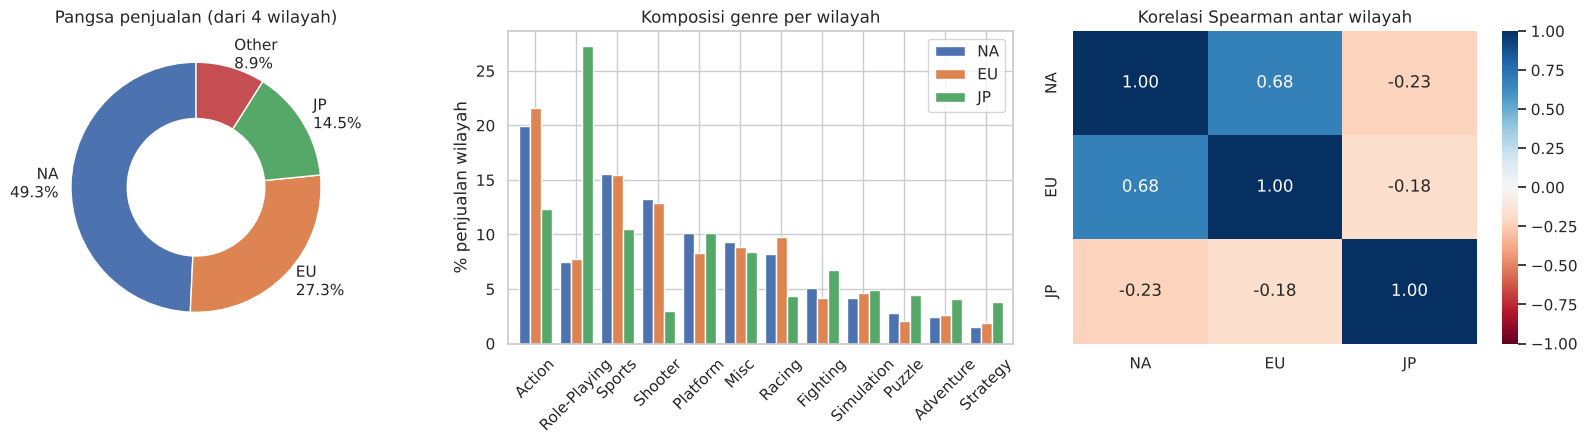

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))

sh = pd.Series(R1["share_of_4_regions_pct"])
ax[0].pie(sh.values, labels=[f"{k}\n{v:.1f}%" for k, v in sh.items()], startangle=90,
          wedgeprops=dict(width=0.45, edgecolor="white"))
ax[0].set_title("Pangsa penjualan (dari 4 wilayah)")

g = pd.read_csv(f"{OUT}/rq1_genre_share_by_region.csv", index_col=0)
g = g.loc[g.mean(axis=1).sort_values(ascending=False).index]
g.columns = ["NA", "EU", "JP"]
g.plot.bar(ax=ax[1], width=0.8)
ax[1].set_title("Komposisi genre per wilayah"); ax[1].set_ylabel("% penjualan wilayah"); ax[1].set_xlabel("")
ax[1].tick_params(axis="x", rotation=45)

sp = pd.DataFrame(R1["spearman"]).loc[["NA_Sales","EU_Sales","JP_Sales"], ["NA_Sales","EU_Sales","JP_Sales"]]
sns.heatmap(sp, annot=True, fmt=".2f", cmap="RdBu", vmin=-1, vmax=1, ax=ax[2], xticklabels=["NA","EU","JP"], yticklabels=["NA","EU","JP"])
ax[2].set_title("Korelasi Spearman antar wilayah")
plt.tight_layout(); plt.show()

Jarak genre (Jensen-Shannon): NA-EU=0.050, NA-JP=0.301, EU-JP=0.309
CI95% bootstrap: NA-EU [0.042, 0.073], NA-JP [0.283, 0.329] -> tidak tumpang-tindih: komposisi genre Jepang berbeda nyata dari Barat


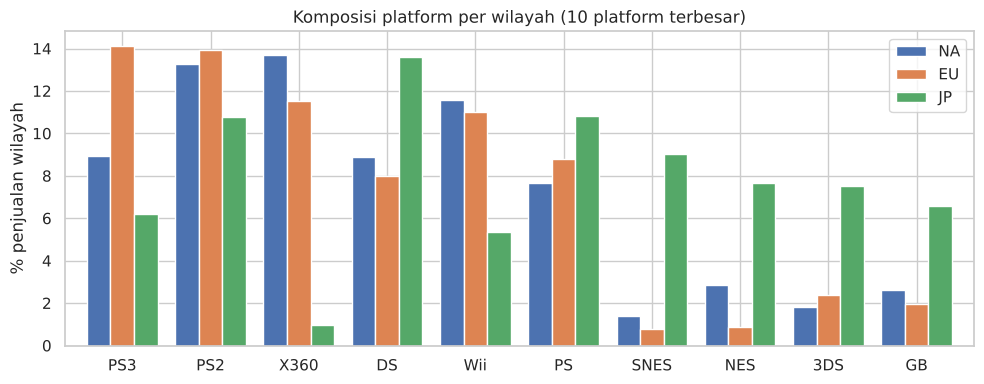

In [6]:
p = pd.read_csv(f"{OUT}/rq1_platform_share_by_region.csv", index_col=0)
p.columns = ["NA", "EU", "JP"]
p = p.loc[p.max(axis=1).sort_values(ascending=False).head(10).index]
ax = p.plot.bar(figsize=(10, 4), width=0.8)
ax.set_title("Komposisi platform per wilayah (10 platform terbesar)"); ax.set_ylabel("% penjualan wilayah"); ax.set_xlabel("")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

js, ci = R1["by_dimension"]["Genre"]["js"], R1["genre_js_bootstrap_ci95"]
print(f"Jarak genre (Jensen-Shannon): NA-EU={js['NA-EU']:.3f}, NA-JP={js['NA-JP']:.3f}, EU-JP={js['EU-JP']:.3f}")
print(f"CI95% bootstrap: NA-EU {ci['NA-EU']}, NA-JP {ci['NA-JP']} ->",
      "tidak tumpang-tindih: komposisi genre Jepang berbeda nyata dari Barat" if ci['NA-EU'][1] < ci['NA-JP'][0]
      else "tumpang-tindih: perbedaan belum meyakinkan")

## 3. RQ2: Prediksi penjualan global dari atribut produk
Protokol (di `rq.prep` dan `GroupKFold`): 5-fold, dibagi **per judul**; median tahun, pooling publisher (jumlah < 50 menjadi
"Other publishers"; 'N/A' dan 'Unknown' digabung), dan scaler dihitung dari data latih saja. Model: baseline mean dan median,
Random Forest, HistGradientBoosting (loss kuadrat dan loss MAE), serta MLP 128-128.

Bagian ini memakan waktu sekitar 4 menit (Random Forest 300 pohon dan permutation importance). Setel `QUICK = True` untuk uji cepat.

In [7]:
R2 = rq.rq2(df, OUT, QUICK)


RQ2 -- Prediksi penjualan global dari atribut produk (tanpa kebocoran)
  fitur: Year, Platform, Genre, Publisher (pooled)  -> 91 kolom setelah encoding
  judul unik = 11,493 ; split = GroupKFold(5) per judul, statistik dari train saja

  Model                                MAE            RMSE              R2
  Baseline (mean)             0.591+/-0.030    1.506+/-0.382   -0.001+/-0.001
  Baseline (median)           0.467+/-0.044    1.550+/-0.382   -0.064+/-0.014
  Random Forest               0.493+/-0.036    1.430+/-0.326    0.087+/-0.042
  HistGradientBoosting        0.494+/-0.034    1.402+/-0.349    0.129+/-0.042
  HGB (MAE loss)              0.411+/-0.041    1.464+/-0.384    0.056+/-0.016
  MLP (128-128)               0.513+/-0.023    1.395+/-0.370    0.145+/-0.020
  (mean +/- SD antar 5 fold; setiap judul diuji tepat satu kali)

  Demo kebocoran (HGB, metrik gabungan 16.598 prediksi OOF):
    split acak + statistik global (gaya notebook) : MAE=0.500 RMSE=1.464 R2=+0.114
    split 

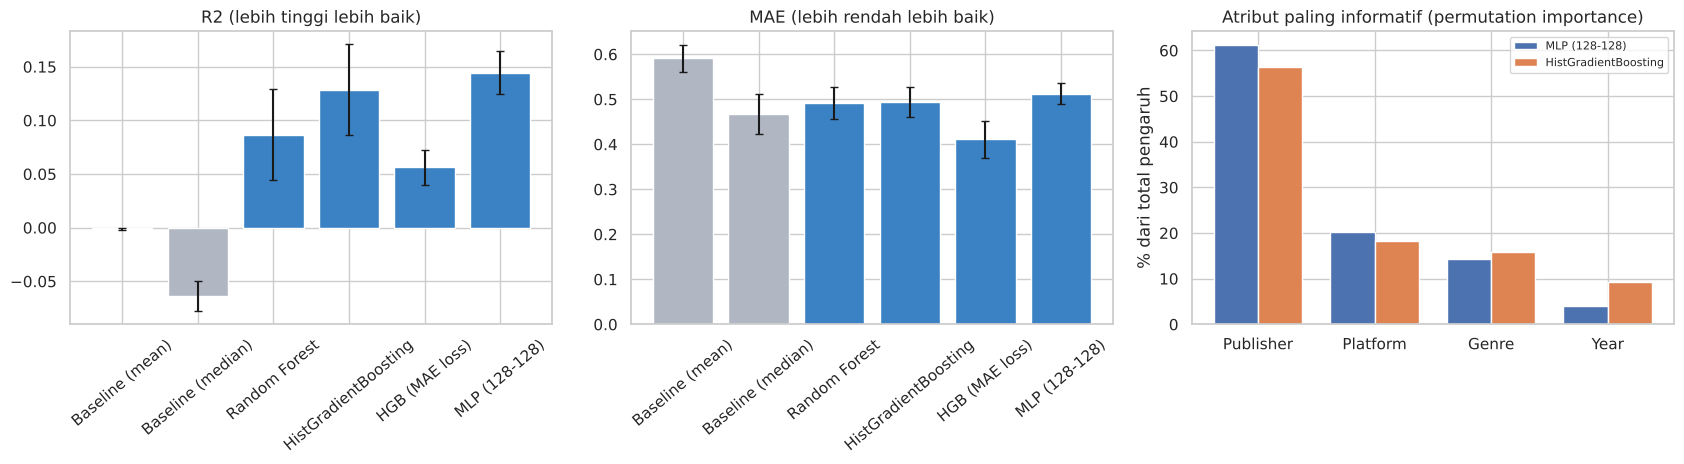

In [8]:
cv = R2["cv"]; names = list(cv)
is_base = [n.startswith("Baseline") for n in names]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for a, metric, title in zip(ax[:2], ["R2", "MAE"], ["R2 (lebih tinggi lebih baik)", "MAE (lebih rendah lebih baik)"]):
    a.bar(names, [cv[n][metric][0] for n in names], yerr=[cv[n][metric][1] for n in names], capsize=3,
          color=["#b0b7c3" if b else "#3b82c4" for b in is_base])
    a.set_title(title); a.tick_params(axis="x", rotation=40)

imp = R2["importance"]; feats = ["Publisher", "Platform", "Genre", "Year"]
w = 0.38
for i, m in enumerate(imp):
    ax[2].bar(np.arange(4) + (i - 0.5) * w, [imp[m][f]["share_pct"] for f in feats], width=w, label=m)
ax[2].set_xticks(range(4)); ax[2].set_xticklabels(feats); ax[2].set_ylabel("% dari total pengaruh")
ax[2].set_title("Atribut paling informatif (permutation importance)"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [9]:
rows = [{"Model": n, **{k: f"{cv[n][k][0]:.3f} +/- {cv[n][k][1]:.3f}" for k in ["MAE", "RMSE", "R2"]}} for n in names]
display_tbl = pd.DataFrame(rows).set_index("Model")
print(display_tbl.to_string())

cands = [n for n in names if not n.startswith("Baseline")]
best_r2 = max(cands, key=lambda n: cv[n]["R2"][0]); best_mae = min(cands, key=lambda n: cv[n]["MAE"][0])
med = cv["Baseline (median)"]["MAE"][0]
print(f"\nR2 terbaik : {best_r2} ({cv[best_r2]['R2'][0]:.3f}) -> atribut produk menjelaskan sekitar {cv[best_r2]['R2'][0]*100:.0f}% variasi.")
print(f"MAE terbaik: {best_mae} ({cv[best_mae]['MAE'][0]:.3f}) vs baseline median {med:.3f}.")
print("Model berloss kuadrat tidak mengalahkan baseline median pada MAE (target sangat miring ke kanan); keunggulannya ada di RMSE/R2.")

ld = R2["leakage_demo"]
a, b = ld["leaky_random_split_global_stats"], ld["clean_grouped_train_only"]
print(f"\nDemo kebocoran (HGB, prediksi out-of-fold gabungan): split acak+statistik global R2={a['R2']:.3f} | per judul+train saja R2={b['R2']:.3f}")
print("Selisihnya kecil: protokol per judul dipakai sebagai pengaman desain, bukan karena terbukti mengubah skor secara berarti.")

                                  MAE             RMSE                R2
Model                                                                   
Baseline (mean)       0.591 +/- 0.030  1.506 +/- 0.382  -0.001 +/- 0.001
Baseline (median)     0.467 +/- 0.044  1.550 +/- 0.382  -0.064 +/- 0.014
Random Forest         0.493 +/- 0.036  1.430 +/- 0.326   0.087 +/- 0.042
HistGradientBoosting  0.494 +/- 0.034  1.402 +/- 0.349   0.129 +/- 0.042
HGB (MAE loss)        0.411 +/- 0.041  1.464 +/- 0.384   0.056 +/- 0.016
MLP (128-128)         0.513 +/- 0.023  1.395 +/- 0.369   0.145 +/- 0.020

R2 terbaik : MLP (128-128) (0.145) -> atribut produk menjelaskan sekitar 14% variasi.
MAE terbaik: HGB (MAE loss) (0.411) vs baseline median 0.467.
Model berloss kuadrat tidak mengalahkan baseline median pada MAE (target sangat miring ke kanan); keunggulannya ada di RMSE/R2.

Demo kebocoran (HGB, prediksi out-of-fold gabungan): split acak+statistik global R2=0.114 | per judul+train saja R2=0.135
Selisihnya kecil

## 4. RQ3: Segmentasi K-Means dari pola penjualan regional
Fitur: log(1 + penjualan) NA, EU, JP, lalu standardisasi (penjualan sangat miring ke kanan). Dua baris dengan NA+EU+JP = 0 dikeluarkan.
Jumlah cluster ditinjau pada k = 2 sampai 8 dengan inertia (elbow), silhouette, Davies-Bouldin, dan Calinski-Harabasz.
Jika `K = None`, dipakai k dengan silhouette tertinggi untuk k >= 3; k = 2 hanya memisahkan "terjual" dan "hampir tidak terjual".

In [10]:
R3 = rq.rq3(df, OUT, K)


RQ3 -- Segmentasi K-Means dari pola penjualan regional (NA, EU, JP)
  baris dipakai: 16,596 dari 16,598 (dibuang 2 baris yang NA+EU+JP = 0)
  fitur: log(1+penjualan) NA/EU/JP, lalu standardisasi (penjualan sangat miring ke kanan)

     k     inertia  silhouette  Davies-B  Calinski-H
     2     29995.8       0.736     0.885       10949
     3     22650.0       0.668     0.948        9940
     4     17294.4       0.658     0.802       10391
     5     13876.2       0.582     0.822       10734
     6     12037.2       0.565     0.808       10406
     7     10483.4       0.493     0.889       10366
     8      9510.8       0.475     0.908       10036

  elbow (jarak maks. ke garis ujung) : k=5
  silhouette tertinggi               : k=2 (0.736); untuk k>=3: k=3 (0.668)
  k yang dipakai                     : 3  (silhouette=0.668)  <- BUKAN optimum mutlak; k=2 hanya memisah 'terjual/hampir tidak'; dipilih agar segmen bisa diprofilkan
  stabilitas (ARI vs 7 seed lain)    : 0.994

  Profil seg

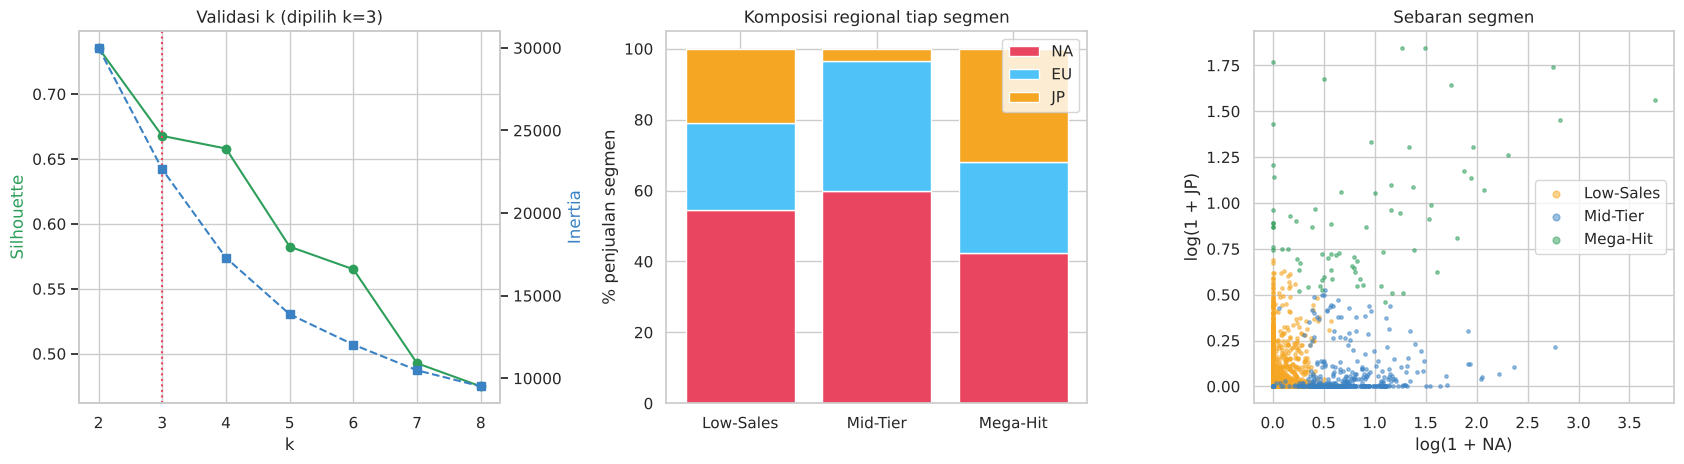

In [11]:
ks = pd.DataFrame(R3["k_table"]); prof = pd.read_csv(f"{OUT}/rq3_profile.csv"); segs = list(prof["Segmen"])
asg = pd.read_csv(f"{OUT}/rq3_assignments.csv")
palette = dict(zip(segs, ["#f5a623", "#3b82c4", "#2e9e5b", "#e94560", "#7b61ff", "#66bb6a", "#ff8a65", "#90a4ae"]))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
ax[0].plot(ks["k"], ks["silhouette"], "o-", color="#2e9e5b", label="Silhouette")
ax[0].set_xlabel("k"); ax[0].set_ylabel("Silhouette", color="#2e9e5b")
ax0b = ax[0].twinx(); ax0b.plot(ks["k"], ks["inertia"], "s--", color="#3b82c4"); ax0b.set_ylabel("Inertia", color="#3b82c4"); ax0b.grid(False)
ax[0].axvline(R3["chosen_k"], color="#e94560", ls=":"); ax[0].set_title(f"Validasi k (dipilih k={R3['chosen_k']})")

bottom = np.zeros(len(prof))
for r, c in zip(["NA", "EU", "JP"], ["#e94560", "#4fc3f7", "#f5a623"]):
    ax[1].bar(prof["Segmen"], prof[f"{r}_share%"], bottom=bottom, label=r, color=c); bottom += prof[f"{r}_share%"].values
ax[1].set_title("Komposisi regional tiap segmen"); ax[1].set_ylabel("% penjualan segmen"); ax[1].legend()

smp = asg.sample(min(4000, len(asg)), random_state=42)
for s in segs:
    m = smp[smp["Segmen"] == s]
    ax[2].scatter(np.log1p(m["NA_Sales"]), np.log1p(m["JP_Sales"]), s=6, alpha=0.5, color=palette[s], label=s)
ax[2].set_xlabel("log(1 + NA)"); ax[2].set_ylabel("log(1 + JP)"); ax[2].set_title("Sebaran segmen"); ax[2].legend(markerscale=2)
plt.tight_layout(); plt.show()

In [12]:
print(prof.round(2).to_string(index=False))
top, low = prof.iloc[-1], prof.iloc[0]; lowest_jp = prof.sort_values("JP_share%").iloc[0]
print(f"\n{int(top['n']):,} record ({top['pct']:.1f}%) di segmen {top['Segmen']} (rata-rata {top['mean_global']:.2f} juta kopi); "
      f"{low['pct']:.1f}% di segmen {low['Segmen']} (rata-rata {low['mean_global']:.2f} juta).")
print(f"Porsi Jepang terendah: segmen {lowest_jp['Segmen']} ({lowest_jp['JP_share%']:.1f}% dari penjualannya).")
sil = {r["k"]: r["silhouette"] for r in R3["k_table"]}
print(f"k={R3['chosen_k']}: silhouette {sil[R3['chosen_k']]:.3f}, stabilitas ARI {R3['stability_ARI_mean']:.3f}; "
      f"silhouette tertinggi k={R3['best_silhouette_k']} ({sil[R3['best_silhouette_k']]:.3f}); elbow k={R3['elbow_k']}.")

   Segmen     n  mean_global  median_global   NA   EU   JP   pct  NA_share%  EU_share%  JP_share%
Low-Sales 14495         0.22           0.13 0.11 0.05 0.04 87.34      54.38      24.60      21.01
 Mid-Tier  1772         2.15           1.58 1.16 0.71 0.06 10.68      59.86      36.81       3.33
 Mega-Hit   329         5.71           3.19 2.26 1.37 1.70  1.98      42.42      25.67      31.91

329 record (2.0%) di segmen Mega-Hit (rata-rata 5.71 juta kopi); 87.3% di segmen Low-Sales (rata-rata 0.22 juta).
Porsi Jepang terendah: segmen Mid-Tier (3.3% dari penjualannya).
k=3: silhouette 0.668, stabilitas ARI 0.994; silhouette tertinggi k=2 (0.736); elbow k=5.


## 5. Ringkasan klaim dan bukti
Tabel ini dibuat dari hasil di atas supaya klaim di naskah mengikuti angka, bukan sebaliknya.

In [13]:
R = {"n_records": int(len(df)), "n_titles": int(df["Name"].nunique()), "genre_pointer_fixes": n_fix,
     "rq1": R1, "rq2": R2, "rq3": R3}
json.dump(R, open(f"{OUT}/results.json", "w"), indent=2, default=float)     # dibaca oleh app.py
open(f"{OUT}/report.txt", "w", encoding="utf8").write("\n".join(rq.LOG))

js = R1["by_dimension"]["Genre"]["js"]; ci = R1["genre_js_bootstrap_ci95"]
claims = pd.DataFrame([
    ("Dataset", f"{len(df):,} record dan {df['Name'].nunique():,} judul unik", "Tulis 'records', bukan 'titles'."),
    ("RQ1 pangsa", " / ".join(f"{k} {v:.1f}%" for k, v in R1["share_of_4_regions_pct"].items() if k != "Other") + " (dari 4 wilayah)", "Sebutkan penyebut."),
    ("RQ1 asimetri genre", f"JS NA-EU {js['NA-EU']:.2f} vs NA-JP {js['NA-JP']:.2f}; CI " + ("terpisah" if ci['NA-EU'][1] < ci['NA-JP'][0] else "tumpang-tindih"), "Didukung data." if ci['NA-EU'][1] < ci['NA-JP'][0] else "Lemah."),
    ("RQ2 kinerja", f"R2 terbaik {cv[best_r2]['R2'][0]:.3f} ({best_r2}); MAE terbaik {cv[best_mae]['MAE'][0]:.3f} vs median {med:.3f}", "Kinerja prediktif rendah; laporkan apa adanya."),
    ("RQ2 atribut", " > ".join(f"{f} {imp[list(imp)[0]][f]['share_pct']:.0f}%" for f in sorted(feats, key=lambda f: -imp[list(imp)[0]][f]['share_pct'])), "Urutan kasar; SD antar fold besar."),
    ("RQ3 segmen", f"k={R3['chosen_k']}; " + ", ".join(f"{r['Segmen']} {r['pct']:.1f}%" for _, r in prof.iterrows()), f"k bukan optimum mutlak (silhouette terbaik k={R3['best_silhouette_k']})."),
], columns=["Aspek", "Hasil", "Catatan untuk naskah"])
print(claims.to_string(index=False))
print("\ntersimpan:", f"{OUT}/results.json", f"{OUT}/report.txt")

             Aspek                                                               Hasil                             Catatan untuk naskah
           Dataset                                 16,598 record dan 11,493 judul unik                 Tulis 'records', bukan 'titles'.
        RQ1 pangsa                     NA 49.3% / EU 27.3% / JP 14.5% (dari 4 wilayah)                               Sebutkan penyebut.
RQ1 asimetri genre                            JS NA-EU 0.05 vs NA-JP 0.30; CI terpisah                                   Didukung data.
       RQ2 kinerja R2 terbaik 0.145 (MLP (128-128)); MAE terbaik 0.411 vs median 0.467   Kinerja prediktif rendah; laporkan apa adanya.
       RQ2 atribut                  Publisher 61% > Platform 20% > Genre 14% > Year 4%               Urutan kasar; SD antar fold besar.
        RQ3 segmen                 k=3; Low-Sales 87.3%, Mid-Tier 10.7%, Mega-Hit 2.0% k bukan optimum mutlak (silhouette terbaik k=2).

tersimpan: hasil/results.json hasil/report.txt


## Catatan dan keterbatasan
- Atribut produk (genre, platform, publisher, tahun) hanya menjelaskan sebagian kecil variasi penjualan global; hasil ini harus dibaca sebagai batas informasi atribut pra-rilis.
- Urutan permutation importance didasarkan pada lima fold dengan simpangan besar; gunakan sebagai urutan kasar.
- Pemilihan k=3 mengutamakan interpretabilitas segmen dan stabilitas; k=2 memberi silhouette lebih tinggi tetapi hanya membedakan "terjual" dan "hampir tidak terjual".
- Dataset yang sama (VGChartz via Kaggle) juga dipakai peneliti lain; kebaruan terletak pada rancangan terpadu, bukan pada datanya.
- Untuk menjalankan ulang seluruh pipeline dari terminal: `python rq_pipeline.py --sql video_game_sales.sql --out hasil`.